In [19]:
import pandas as pd
from sklearn.cluster import KMeans

data = {
    'Income' : [20,22,25,70,75,84],
    'Spend' : [22,23,26,76,78,85]
}

model = KMeans(n_clusters=2, random_state=42)

df = pd.DataFrame(data)

# Fit the model and assign the cluster labels
df['Cluster'] = model.fit_predict(df)

# Reorder and print the columns in the exact format you requested
output_df = df[['Cluster', 'Income', 'Spend']]
print(output_df.to_string(index=False))

 Cluster  Income  Spend
       0      20     22
       0      22     23
       0      25     26
       1      70     76
       1      75     78
       1      84     85


In [37]:
new_data = [28,34]

new_df = pd.DataFrame([new_data], columns=['Income', 'Spend'])

new_df['Cluster'] = model.predict(new_df)

print(new_df.to_string(index=False))

 Income  Spend  Cluster
     28     34        0


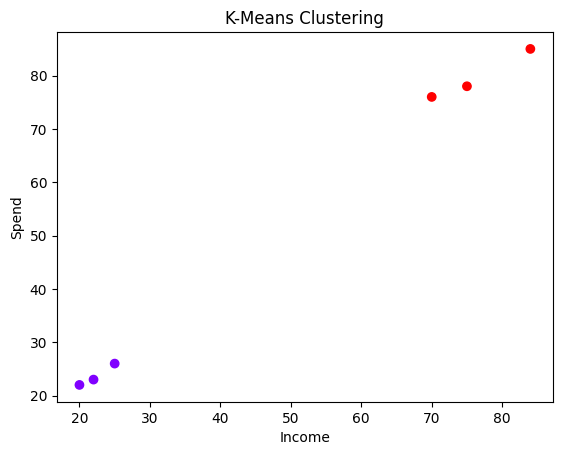

In [34]:
import matplotlib.pyplot as plt

plt.scatter(df['Income'], df['Spend'], c=df['Cluster'], cmap='rainbow')
plt.xlabel('Income')
plt.ylabel('Spend')
plt.title('K-Means Clustering')
plt.show()

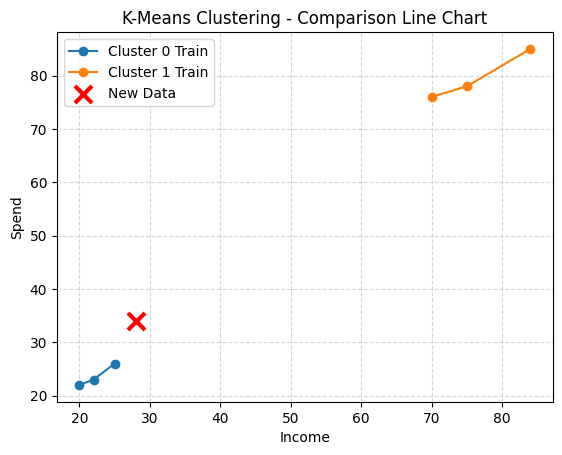

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# Plot the clustered training data as lines/points
for cluster_id in df['Cluster'].unique():
    cluster_data = df[df['Cluster'] == cluster_id].sort_values(by='Income')
    plt.plot(cluster_data['Income'], cluster_data['Spend'], marker='o', label=f'Cluster {cluster_id} Train')

# Plot the new data point for comparison
plt.scatter(new_df['Income'], new_df['Spend'], color='red', marker='x', s=150, linewidths=3, label='New Data')

plt.xlabel('Income')
plt.ylabel('Spend')
plt.title('K-Means Clustering - Comparison Line Chart')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [39]:
%%capture
!pip install gradio

In [ ]:
import gradio as gr
import pandas as pd
import numpy as np

def predict_customer_category(income, spend):
    # Create a DataFrame for the prediction input
    input_data = pd.DataFrame([[income, spend]], columns=['Income', 'Spend'])

    # Predict cluster (0 or 1)
    cluster_pred = model.predict(input_data)[0]

    # Map cluster numbers to meaningful categories
    # Cluster 1 has higher average income/spend (~70-84), mapping to 'VIP Customer'
    # Cluster 0 has lower average income/spend (~20-25), mapping to 'Regular Customer'
    if cluster_pred == 1:
        category = "VIP Customer"
        description = "High Income, High Spending pattern."
    else:
        category = "Regular Customer"
        description = "Standard Income, Moderate/Low Spending pattern."

    return f"Category: {category}", f"Assigned Cluster: {cluster_pred}\nDescription: {description}"

# Create the Gradio interface
interface = gr.Interface(
    fn=predict_customer_category,
    inputs=[
        gr.Number(label="Monthly Income (e.g., 20 or 75)", value=25),
        gr.Number(label="Monthly Spend (e.g., 22 or 78)", value=26)
    ],
    outputs=[
        gr.Textbox(label="Customer Segment"),
        gr.Textbox(label="Segment Details")
    ],
    title="Real-Time Customer Segment Predictor (K-Means)",
    description="Enter a customer's monthly income and spend amount to dynamically classify them using the trained K-Means model."
)

# Launch the application in Colab
interface.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7c9969974d3020d203.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
